In [1]:
# Import Required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Load Dataset
df = pd.read_csv("/content/construction_material_cost_dataset_300_records.csv")
df.head()

,Project_ID,Structure_Type,Length_m,Width_m,Height_m,Thickness_m,Area_m2,Volume_m3,Material,Quantity,Unit,Unit_Price_INR,Material_Cost_INR,Total_Project_Cost_INR
0,P001,House,9.34,12.67,2.97,0.23,118.34,351.46,Bricks,19598.00,Pieces,8,156784.00,324416.65
1,P001,House,9.34,12.67,2.97,0.23,118.34,351.46,Cement,235.00,Bags,403,94705.00,324416.65
2,P001,House,9.34,12.67,2.97,0.23,118.34,351.46,Sand,20.85,m³,1295,27000.75,324416.65
3,P001,House,9.34,12.67,2.97,0.23,118.34,351.46,Steel,752.90,kg,61,45926.90,324416.65
4,P002,Wall,12.09,0.23,2.54,0.23,30.71,7.06,Bricks,3277.00,Pieces,12,39324.00,54578.22


In [ ]:
# Uderstanding the dataset
df.shape

(300, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Project_ID              300 non-null    object 
 1   Structure_Type          300 non-null    object 
 2   Length_m                300 non-null    float64
 3   Width_m                 300 non-null    float64
 4   Height_m                300 non-null    float64
 5   Thickness_m             300 non-null    float64
 6   Area_m2                 300 non-null    float64
 7   Volume_m3               300 non-null    float64
 8   Material                300 non-null    object 
 9   Quantity                300 non-null    float64
 10  Unit                    300 non-null    object 
 11  Unit_Price_INR          300 non-null    int64  
 12  Material_Cost_INR       300 non-null    float64
 13  Total_Project_Cost_INR  300 non-null    float64
dtypes: float64(9), int64(1), object(4)
memory 

In [6]:
df.describe()

,Length_m,Width_m,Height_m,Thickness_m,Area_m2,Volume_m3,Quantity,Unit_Price_INR,Material_Cost_INR,Total_Project_Cost_INR
count,300.000000,300.000000,300.000000,3.000000e+02,300.000000,300.000000,300.000000,300.000000,300.00000,300.000000
mean,10.165867,4.988667,3.140800,2.300000e-01,63.448667,161.351600,3296.401100,560.810000,55029.28790,220117.151600
std,4.986312,4.116401,0.315015,1.000870e-15,54.189678,197.580274,7938.692339,705.730794,80604.86917,212734.955125
min,3.120000,0.230000,2.510000,2.300000e-01,13.000000,4.100000,0.100000,8.000000,6.90000,25852.580000
25%,5.200000,0.230000,2.920000,2.300000e-01,26.900000,11.890000,21.532500,44.250000,6659.22000,80072.100000
50%,9.340000,5.140000,3.120000,2.300000e-01,40.830000,75.970000,63.600000,237.500000,24122.25000,111096.600000
75%,14.500000,7.590000,3.370000,2.300000e-01,79.460000,255.140000,1690.825000,696.000000,66265.38750,378317.200000
max,19.740000,14.030000,3.860000,2.300000e-01,249.450000,773.310000,46193.000000,2186.000000,436513.00000,817551.240000


In [7]:
# Check missing values
df.isnull().sum()

,0
Project_ID,0
Structure_Type,0
Length_m,0
Width_m,0
Height_m,0
Thickness_m,0
Area_m2,0
Volume_m3,0
Material,0
Quantity,0


In [8]:
# Check Duplicate data
df.duplicated().sum()

np.int64(0)

In [9]:
# Explore the Data
# Check different stucture types
df["Structure_Type"].value_counts()

,count
Structure_Type,
Room,112
Wall,100
House,88


In [10]:
# Check Different materials
df["Material"].value_counts()

,count
Material,
Bricks,75
Cement,75
Sand,75
Steel,75


In [11]:
# Find total Material cost
df["Material_Cost_INR"].sum()

np.float64(16508786.37)

In [12]:
# Find the most Expensive material
df.groupby("Material")["Material_Cost_INR"].sum().sort_values(ascending=False)

,Material_Cost_INR
Material,
Bricks,9752908.00
Cement,4013285.80
Sand,1389630.67
Steel,1352961.90


In [13]:
# Find Total cost of all projects
total_cost = df["Total_Project_Cost_INR"].sum()
print("Total Construction Cost:", total_cost)

Total Construction Cost: 66035145.48


In [14]:
# Find Average Project Cost
average_cost = df["Total_Project_Cost_INR"].mean()
print("Average Project Cost:", average_cost)

Average Project Cost: 220117.15159999998


In [15]:
# Find Minimum and Maximum Project cost
minimum_cost = df["Total_Project_Cost_INR"].min()
maximum_cost = df["Total_Project_Cost_INR"].max()
print("Minimum Project Cost:", minimum_cost)
print("Maximum Project Cost:", maximum_cost)

Minimum Project Cost: 25852.58
Maximum Project Cost: 817551.24


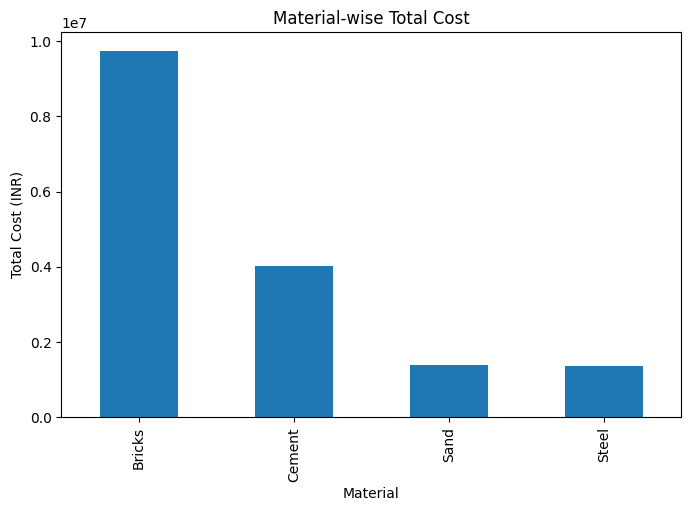

In [16]:
# Create avisualization
# Graph 1: Material-wise Total Cost
material_cost = df.groupby("Material")["Material_Cost_INR"].sum()
material_cost.plot(
    kind = "bar",
    figsize=(8,5)
)
plt.title("Material-wise Total Cost")
plt.xlabel("Material")
plt.ylabel("Total Cost (INR)")
plt.show()

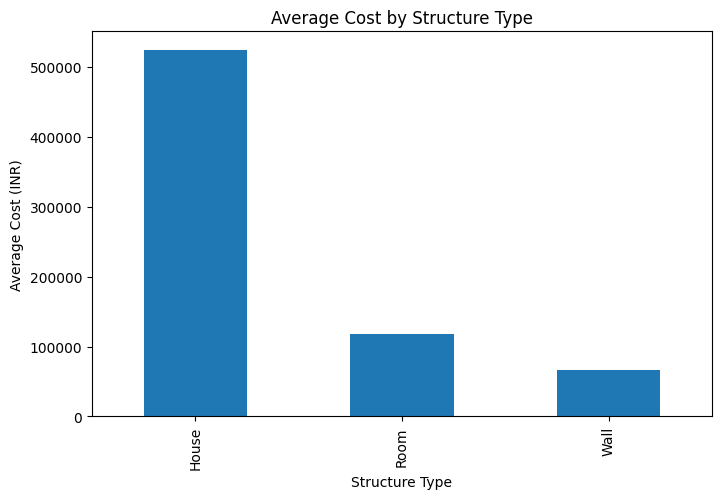

In [17]:
# Graph 2: Structure-wise Cost
structure_cost = df.groupby("Structure_Type")["Total_Project_Cost_INR"].mean()

structure_cost.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Cost by Structure Type")
plt.xlabel("Structure Type")
plt.ylabel("Average Cost (INR)")
plt.show()

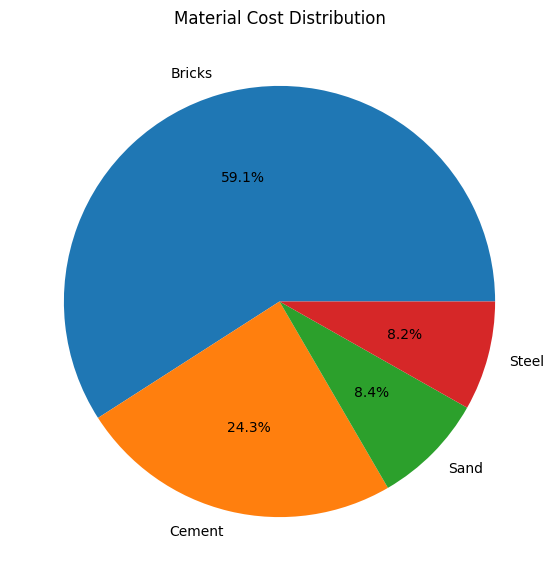

In [19]:
# Graph 3: Material Cost distribution
material_cost.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Material Cost Distribution")
plt.ylabel("")
plt.show()

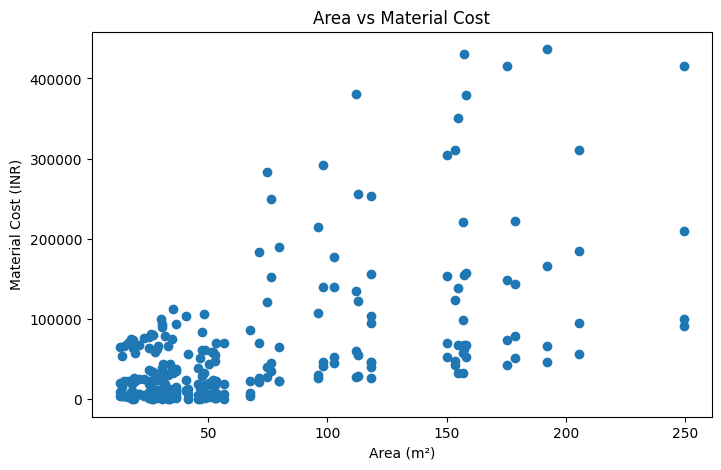

In [20]:
# Graph 4: Area Vs Material Cost
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Area_m2"],
    df["Material_Cost_INR"]
)

plt.title("Area vs Material Cost")
plt.xlabel("Area (m²)")
plt.ylabel("Material Cost (INR)")
plt.show()

In [21]:
# Total quantity of each material
material_quantity = df.groupby("Material")["Quantity"].sum()
print(material_quantity)

Material
Bricks    958373.00
Cement      8820.40
Sand         853.93
Steel      20873.00
Name: Quantity, dtype: float64


In [22]:
# Average price of each material
average_price = df.groupby("Material")["Unit_Price_INR"].mean()
print(average_price)

Material
Bricks      10.360000
Cement     456.866667
Sand      1712.506667
Steel       63.506667
Name: Unit_Price_INR, dtype: float64


In [23]:
# Most used material
most_used = material_quantity.idxmax()
print("Most Used Material:", most_used)

Most Used Material: Bricks


In [24]:
# Most expensive material
material_cost = df.groupby("Material")["Material_Cost_INR"].sum()
most_expensive = material_cost.idxmax()
print("Most Expensive Material:", most_expensive)

Most Expensive Material: Bricks


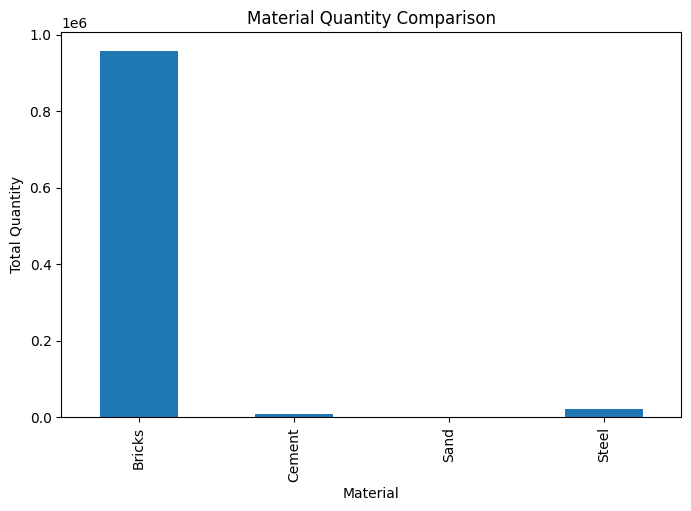

In [25]:
# Material Quantity Comparison
material_quantity.plot(
    kind="bar",
    figsize=(8,5)
)
plt.title("Material Quantity Comparison")
plt.xlabel("Material")
plt.ylabel("Total Quantity")
plt.show()

In [26]:
# Material-wise summary
summary = df.groupby("Material").agg({
    "Quantity": "sum",
    "Unit_Price_INR": "mean",
    "Material_Cost_INR": "sum"
})
print(summary)

           Quantity  Unit_Price_INR  Material_Cost_INR
Material                                              
Bricks    958373.00       10.360000         9752908.00
Cement      8820.40      456.866667         4013285.80
Sand         853.93     1712.506667         1389630.67
Steel      20873.00       63.506667         1352961.90


In [27]:
# Project-wise total Cost
project_cost = df.groupby("Project_ID")["Total_Project_Cost_INR"].first()
print(project_cost)

Project_ID
P001    324416.65
P002     54578.22
P003     62957.11
P004    300696.72
P005    102702.50
          ...    
P071    519994.19
P072    119001.44
P073    149920.20
P074     96653.15
P075    658531.62
Name: Total_Project_Cost_INR, Length: 75, dtype: float64


In [28]:
# Find the most expensive project
highest_project = project_cost.idxmax()
highest_cost = project_cost.max()
print("Highest Cost Project:", highest_project)
print("Cost:", highest_cost)

Highest Cost Project: P045
Cost: 817551.24


In [29]:
# Find the cheapest project
lowest_project = project_cost.idxmin()
lowest_cost = project_cost.min()
print("Lowest Cost Project:", lowest_project)
print("Cost:", lowest_cost)

Lowest Cost Project: P019
Cost: 25852.58


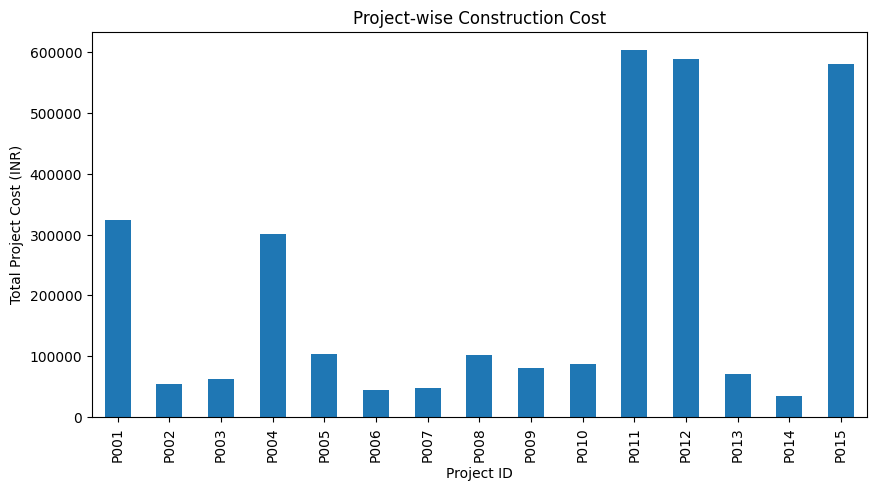

In [30]:
# Visualize Project costs
project_cost.head(15).plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Project-wise Construction Cost")
plt.xlabel("Project ID")
plt.ylabel("Total Project Cost (INR)")
plt.show()